## Asset Class Galaxy


### Settings


In [1]:
# Set refresh_timeseries=True to download timeseries. Otherwise symbol-cache is used.
refresh_timeseries = False
throttle_limit = 100
wait_time = 30


In [2]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}


<IPython.core.display.Javascript object>

### Build asset-classes.csv


AGG 

AOA 

AOK 

AOM 

AOR 

...

XLP 

XLRE 

XLU 

XLV 

XLY 

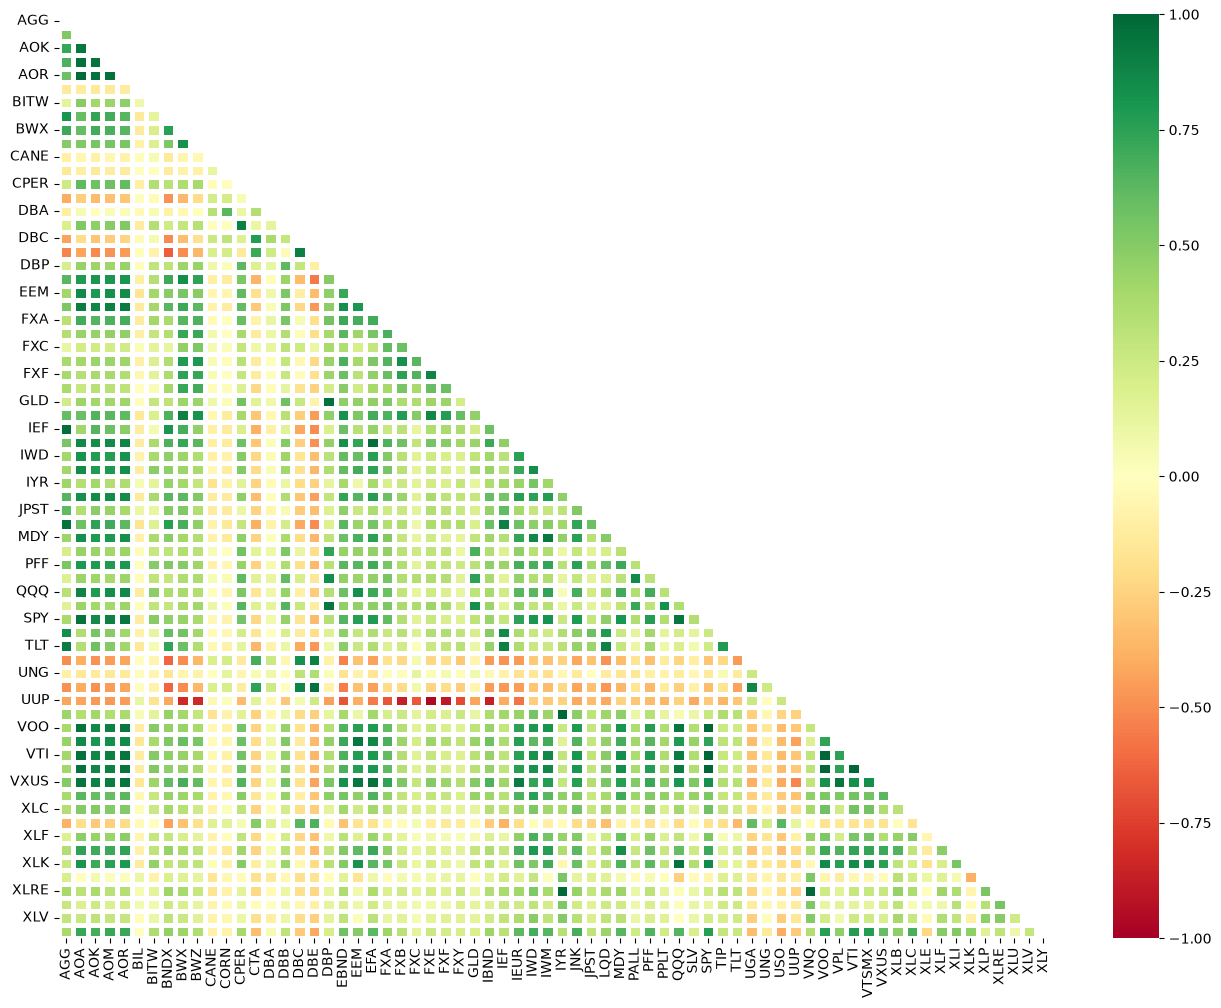

In [3]:
from pathlib import Path

import pandas as pd

import brownbear as bb

bb.notebook_display_options()

directory = Path('.')

# asset2etf maps each asset class to a representative ETF.
asset2etf = pd.read_csv('asset-classes-2-etf.csv', skip_blank_lines=True, comment='#')
asset2etf = asset2etf.set_index(['Asset Class'])['ETF'].to_dict()
symbols = sorted(set(asset2etf.values()))

bb.fetch_timeseries(symbols, refresh=refresh_timeseries, throttle_limit=throttle_limit, wait_time=wait_time)
bb.compile_timeseries(symbols, output_path=directory / 'symbols-timeseries.csv')

df = pd.read_csv('symbols-timeseries.csv', skip_blank_lines=True, comment='#')
df.set_index("Date", inplace=True)

corr_map = bb.correlation_map(df, method='log', days=bb.TRADING_DAYS_PER_YEAR)

with open('asset-classes-in.csv') as f:
    lines = [line.strip() for line in f]

out = []
for line in lines:
    if not line or line.startswith('#'):
        out.append(line)
        continue
    fields = [field.strip() for field in line.split(',')]
    assetA = fields[0].strip('"')
    assetB = fields[1].strip('"')
    if assetA == assetB or assetA == 'Asset Class A':
        out.append(line)
        continue
    etfA = asset2etf[assetA]
    etfB = asset2etf[assetB]
    corrAB = corr_map.loc[etfA, etfB]
    out.append(f'"{assetA}","{assetB}","{corrAB:0.2f}"')

with open('asset-classes.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')


### Build investment-options.csv


In [4]:
import numpy as np

metrics = bb.compute_investment_metrics(df)

with open('investment-options-in.csv') as f:
    out = [line.strip() for line in f]

for asset_class, symbol in asset2etf.items():
    ret_3mo = metrics['annual_returns_3mo'][symbol]
    ret_6mo = metrics['annual_returns_6mo'][symbol]
    ret_1yr = metrics['annual_returns_1yr'][symbol]
    ret_1_1yr = metrics['annual_returns_1_1yr'][symbol]
    ret_3yr = metrics['annual_returns_3yr'][symbol]
    ret_5yr = metrics['annual_returns_5yr'][symbol]
    if np.isnan(ret_3yr):
        ret_3yr = ret_1yr
    if np.isnan(ret_5yr):
        ret_5yr = ret_3yr
    vola = metrics['vola'][symbol] * 100
    ds_vola = metrics['ds_vola'][symbol] * 100
    sd_1yr = metrics['std_dev_1yr'][symbol] * 100
    sd_3yr = metrics['std_dev_3yr'][symbol] * 100
    sd_5yr = metrics['std_dev_5yr'][symbol] * 100
    out.append(
        f'"{asset_class}","{asset_class}","{asset_class}",'
        f'"{ret_3mo:0.2f}","{ret_6mo:0.2f}","{ret_1yr:0.2f}","{ret_1_1yr:0.2f}","{ret_3yr:0.2f}",'
        f'"{ret_5yr:0.2f}","{vola:0.2f}","{ds_vola:0.2f}","{sd_1yr:0.2f}","{sd_3yr:0.2f}","{sd_5yr:0.2f}"'
    )

with open('investment-options.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')

investment_options = pd.read_csv('investment-options.csv', skip_blank_lines=True, comment='#')
investment_options


,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr
0,US Stocks,US Stocks,US Stocks,8.84,26.86,20.24,21.02,21.37,12.16,10.77,4.16,12.46,13.19,16.03
1,Global Stocks,Global Stocks,Global Stocks,8.90,10.26,26.14,26.36,20.28,9.84,11.13,6.02,13.34,11.92,15.09
2,US Bonds,US Bonds,US Bonds,-2.29,-3.78,1.97,2.43,4.34,-0.28,4.27,2.17,3.11,5.54,6.41
3,Global Bonds,Global Bonds,Global Bonds,-3.18,-3.76,1.02,1.26,3.90,-0.13,3.81,2.01,3.30,4.19,5.29
4,Cash Equivalents,Cash Equivalents,Cash Equivalents,3.56,3.60,3.75,3.74,4.54,3.59,0.16,0.00,0.10,0.21,0.52
5,Real Estate,Real Estate,Real Estate,10.40,7.35,9.81,10.96,10.49,2.03,11.09,6.62,13.09,16.48,18.97
6,Commodities,Commodities,Commodities,19.00,50.48,44.40,44.86,13.35,14.60,20.81,10.88,22.60,16.15,17.12
7,Currencies,Currencies,Currencies,7.73,8.29,6.01,5.45,4.08,5.41,4.88,3.46,4.85,6.76,7.08
8,Managed Futures,Managed Futures,Managed Futures,-12.54,-12.10,4.41,4.33,9.42,9.42,30.34,18.63,19.28,15.37,16.66
9,Balanced,Balanced,Balanced,2.76,5.82,10.10,10.52,11.14,4.76,6.28,2.75,6.11,7.05,8.92
